# Fourier Analysis Demo
Showcase of base experiments to analyse Fourier space of solution

## 0 - Setup

In [2]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models  import MerlinHeatQPINN, ClassicalHeatQPINN, MerlinTunableSimple
from src.pde     import HeatEquation, WaveEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import (
    plot_training_history,
    plot_solution_comparison,
    plot_power_spectrum,
    plot_mode_l2_errors,
    plot_frequency_sweep,
    plot_multi_model_l2_error
)
from src.utils import hilbert_space_dimension, quantum_outputsize_for_param_match, find_matching_hidden_readout

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cpu  |  dtype: torch.float32


## 1 - Frequency Sweep
Train both models on heat equatin over a range of IC frequencies

In [22]:
FREQUENCIES = [0.5, 1.0, 1.5, 2, 2.5, 3, 3.5, 4.0, 4.5]
#FREQUENCIES = [1.0, 2.0]
#FREQUENCIES = [3, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0]
C_s = [0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2.0]
#C_s = [0,1.0]
SEEDS = [42, 666, 69, 67, 13]

In [23]:
FEATURE_SIZES_guess = [3]#[2,4,8,16]
FEATURE_SIZE, HIDDEN_READOUT = find_matching_hidden_readout(feature_sizes=FEATURE_SIZES_guess, ranges=[1,100])

print(FEATURE_SIZE)
print(HIDDEN_READOUT)
#select smallest
FEATURE_SIZE = FEATURE_SIZE[0]
HIDDEN_READOUT = HIDDEN_READOUT[0]
QUANTUM_OUTPUT_SIZE = int(quantum_outputsize_for_param_match(FEATURE_SIZE, HIDDEN_READOUT))

[[  1   1]
 [  1   2]
 [  1   3]
 ...
 [ 98 100]
 [ 99 100]
 [100 100]]
[3]
[4]


In [24]:
import numpy as np
import matplotlib.pyplot as plt

def plot_freq_c_performance_diff(
    sweep_results,
    frequencies,
    c_values,
    model_a="classical",
    model_b="qpinn_weights",
    diff_type="relative",      # "absolute", "relative", or "ratio"
    aggregate=np.nanmean,      # how to collapse across seeds
    cmap="RdBu_r",
    annotate=True,
    fmt="{:.1f}",
    figsize=(8, 6),
):
    """
    Plot a (freq, c) grid heatmap of the performance difference between two
    models in sweep_results, aggregated over seeds.

    Expects sweep_results[model] to be a list (one entry per frequency) of:
        {"frequency": freq, "rel_l2": [ [seed_vals...] for each C in c_values ]}

    diff_type:
        "absolute"  -> mean_a - mean_b            (raw rel_l2 units)
        "relative"  -> (mean_a - mean_b) / mean_a * 100   (% improvement of b over a)
        "ratio"     -> mean_a / mean_b
    """

    def extract_matrix(key):
        entries = sweep_results[key]
        mat = np.full((len(frequencies), len(c_values)), np.nan)
        for i, entry in enumerate(entries):
            rel_l2_per_c = entry["rel_l2"]
            for j in range(len(c_values)):
                mat[i, j] = aggregate(rel_l2_per_c[j])
        return mat

    mat_a = extract_matrix(model_a)
    mat_b = extract_matrix(model_b)

    if diff_type == "absolute":
        diff = mat_a - mat_b
        cbar_label = f"{model_a} - {model_b}  (rel_l2)"
        center_zero = True
    elif diff_type == "relative":
        diff = (mat_a - mat_b) / mat_a * 100
        cbar_label = f"% improvement of {model_b} over {model_a}"
        center_zero = True
    elif diff_type == "ratio":
        diff = mat_a / mat_b
        cbar_label = f"{model_a} / {model_b} ratio"
        center_zero = False
    else:
        raise ValueError("diff_type must be 'absolute', 'relative', or 'ratio'")

    fig, ax = plt.subplots(figsize=figsize)

    if center_zero:
        vmax = np.nanmax(np.abs(diff))
        vmin = -vmax
    else:
        vmin, vmax = np.nanmin(diff), np.nanmax(diff)

    im = ax.imshow(diff, origin="lower", aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)

    # ticks/labels use actual freq/c values, not assumed linear spacing
    ax.set_xticks(range(len(c_values)))
    ax.set_xticklabels([f"{c:g}" for c in c_values], rotation=45, ha="right")
    ax.set_yticks(range(len(frequencies)))
    ax.set_yticklabels([f"{f:g}" for f in frequencies])

    ax.set_xlabel("c")
    ax.set_ylabel("freq")
    ax.set_title(f"{model_a} vs {model_b}: {diff_type} performance difference")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)

    if annotate:
        for i in range(len(frequencies)):
            for j in range(len(c_values)):
                val = diff[i, j]
                if not np.isnan(val):
                    ax.text(j, i, fmt.format(val), ha="center", va="center",
                            color="black", fontsize=8)

    plt.tight_layout()
    plt.show()
    return diff  # in case you want the raw matrix for further analysis

In [25]:
sweep_results = {"classical": [], "qpinn_weights": []} #"qpinn": [], 
for freq in FREQUENCIES:
    velocity_results_classical = []
    velocity_results_quantum = []
    for C in C_s:
        #pde = HeatEquation(freq=freq)
        pde = WaveEquation(freq=freq,c=C)
        print(f"\n{'='*60}\nfreq = {freq}, c = {C}")
        #seed_results = {"classical": [], "qpinn_weights": []}
        seed_results_classical = []
        seed_results_quantum = []
        for i,seed in enumerate(SEEDS):
            # --- QPINN ---
    #        qpinn = MerlinHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=pde).to(device)
    #        train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
    #        metrics, _, _, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)
    #        sweep_results["qpinn"].append({"frequency": freq, "rel_l2": metrics["rel_l2"]})
    #        print(f"  QPINN_SEED_{seed}      rel_l2 = {metrics['rel_l2']:.4e}")

            # --- Classical ---
            classical = ClassicalHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, quantum_output_size=QUANTUM_OUTPUT_SIZE, pde = pde).to(device)
            train(model=classical, pde=pde, loss_fn=total_loss, log_every=100, seed=seed, epochs=400)
            metrics, _, _, _, _ = evaluate(model=classical, pde=pde, device=device, dtype=dtype)
            seed_results_classical.append(metrics["rel_l2"])
            #seed_results["classical"].append(metrics["rel_l2"])
            
            print(f"  Classical_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")

            # --- QPINN WEIGHTS ---
            qpinn_weights = MerlinTunableSimple(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=pde).to(device)
            train(model=qpinn_weights, pde=pde, loss_fn=total_loss, log_every=100, seed=seed, epochs=400)
            metrics, _, _, _, _ = evaluate(model=qpinn_weights, pde=pde, device=device, dtype=dtype)
            #seed_results["qpinn_weights"].append(metrics["rel_l2"])
            seed_results_quantum.append(metrics["rel_l2"])

            print(f"  QPINN WEIGHTS_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")
        
        velocity_results_classical.append(seed_results_classical)
        velocity_results_quantum.append(seed_results_quantum)

    sweep_results["classical"].append({"frequency": freq, "rel_l2": velocity_results_classical})
    sweep_results["qpinn_weights"].append({"frequency": freq, "rel_l2": velocity_results_quantum})



freq = 0.5, c = 0
Parameters — total: 177  trainable: 177

Training for 400 epochs on cpu  (dtype=torch.float32)
Epoch     1/400 | Loss: 1.2276e+00 | PDE: 2.83e-04 | Cons: 2.27e+00 | IC: 0.00e+00 | BC: 1.00e+00 | Time: 0.0s
Epoch   100/400 | Loss: 1.0242e+00 | PDE: 1.15e-03 | Cons: 2.31e-01 | IC: 0.00e+00 | BC: 1.00e+00 | Time: 0.3s
Epoch   200/400 | Loss: 1.0002e+00 | PDE: 2.93e-06 | Cons: 2.46e-03 | IC: 0.00e+00 | BC: 1.00e+00 | Time: 0.6s
Epoch   300/400 | Loss: 1.0001e+00 | PDE: 1.80e-06 | Cons: 6.14e-04 | IC: 0.00e+00 | BC: 1.00e+00 | Time: 0.8s
Epoch   400/400 | Loss: 1.0000e+00 | PDE: 1.08e-06 | Cons: 3.75e-04 | IC: 0.00e+00 | BC: 1.00e+00 | Time: 1.2s

Done — 1.2s total
Evaluating on 60×60 grid …
  Relative L2 : 3.5651e-04
  MAE         : 1.6886e-04
  Max abs err : 8.6379e-04
  RMSE        : 2.5209e-04
  Classical_SEED_42   rel_l2 = 3.5651e-04
Parameters — total: 177  trainable: 177

Training for 400 epochs on cpu  (dtype=torch.float32)
Epoch     1/400 | Loss: 1.2924e+00 | PDE

Saved: ../figures/fourier_demo/freq_sweep.png


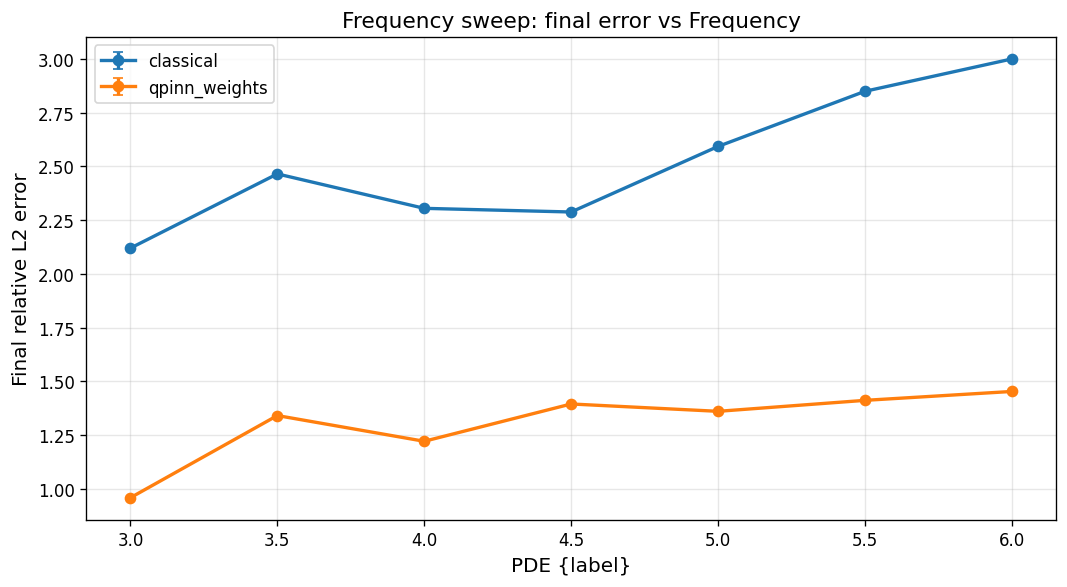

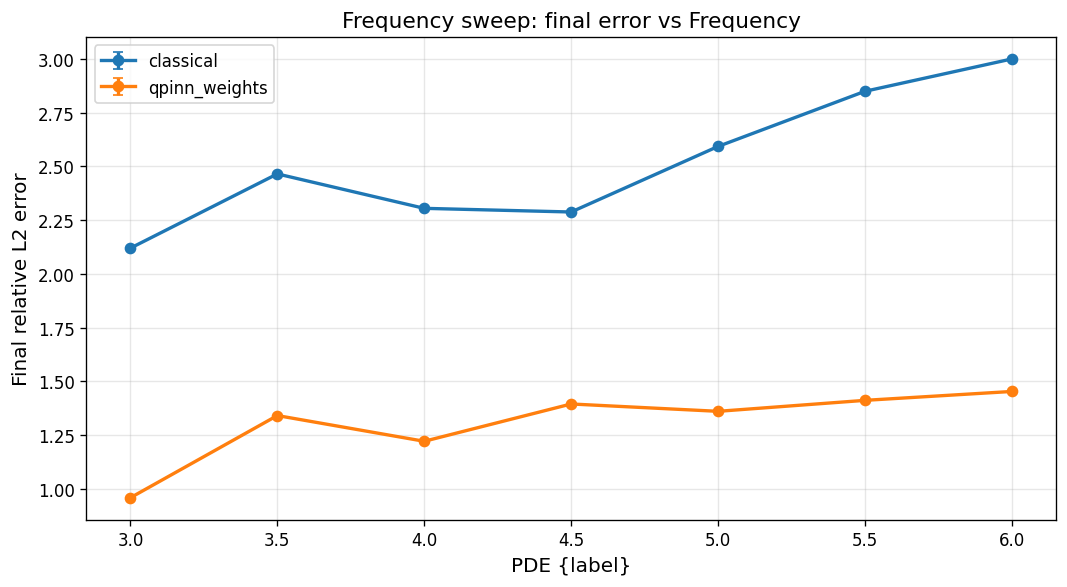

In [50]:
%reload_ext autoreload
plot_frequency_sweep(
    sweep_results,
    save_path = "../figures/fourier_demo/freq_sweep.png",
    show      = True,
)

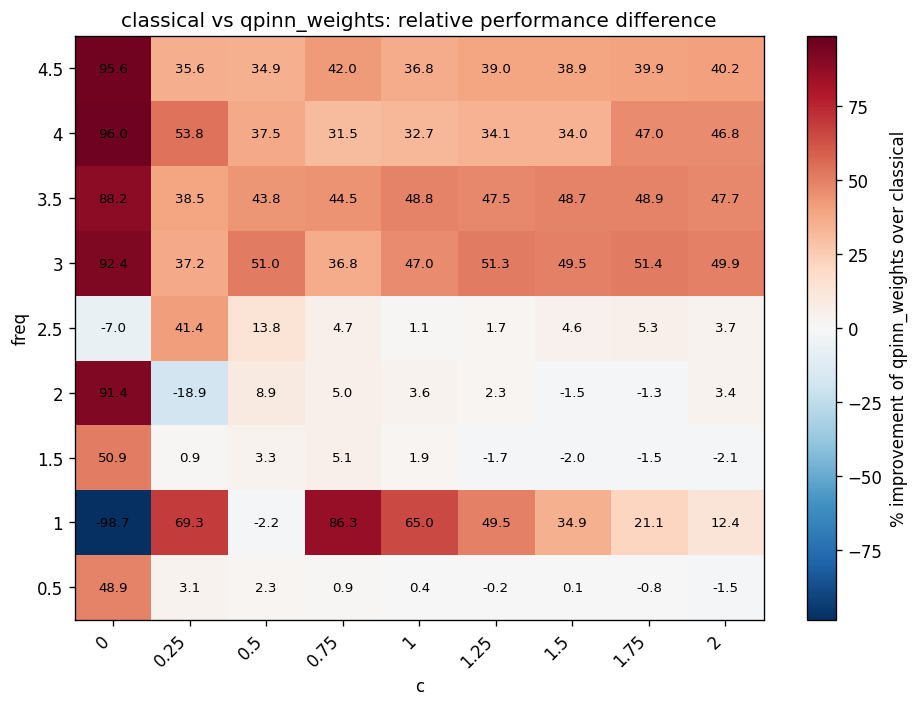

In [26]:
diff_matrix = plot_freq_c_performance_diff(
    sweep_results,
    frequencies=FREQUENCIES,
    c_values=C_s,
    model_a="classical",
    model_b="qpinn_weights",
    diff_type="relative",   # % improvement of qpinn_weights over classical
)

In [28]:
import numpy as np
import matplotlib.pyplot as plt


def _extract_raw(sweep_results, key, n_freq, n_c):
    """Returns array of shape (n_freq, n_c, n_seeds) — ragged-safe via object array fallback."""
    entries = sweep_results[key]
    # figure out n_seeds from first non-empty entry
    n_seeds = len(entries[0]["rel_l2"][0])
    mat = np.full((n_freq, n_c, n_seeds), np.nan)
    for i, entry in enumerate(entries):
        for j in range(n_c):
            vals = entry["rel_l2"][j]
            mat[i, j, :len(vals)] = vals
    return mat


def plot_rel_l2_curves(
    sweep_results,
    frequencies,
    c_values,
    model_a="classical",
    model_b="qpinn_weights",
    labels=("Classical", "QPINN weights"),
    log_scale=True,
    ncols=3,
    figsize_per_ax=(4, 3),
):
    """
    Faceted line plots: one subplot per value of c, x-axis = frequency,
    y-axis = rel_l2, with error bars (std over seeds) for each model.
    """
    n_freq, n_c = len(frequencies), len(c_values)
    raw_a = _extract_raw(sweep_results, model_a, n_freq, n_c)  # (n_freq, n_c, n_seeds)
    raw_b = _extract_raw(sweep_results, model_b, n_freq, n_c)

    mean_a, std_a = np.nanmean(raw_a, axis=2), np.nanstd(raw_a, axis=2)
    mean_b, std_b = np.nanmean(raw_b, axis=2), np.nanstd(raw_b, axis=2)

    nrows = int(np.ceil(n_c / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per_ax[0]*ncols, figsize_per_ax[1]*nrows),
                              squeeze=False)

    for j, c in enumerate(c_values):
        ax = axes[j // ncols][j % ncols]
        ax.errorbar(frequencies, mean_a[:, j], yerr=std_a[:, j], marker="o",
                    label=labels[0], capsize=3)
        ax.errorbar(frequencies, mean_b[:, j], yerr=std_b[:, j], marker="s",
                    label=labels[1], capsize=3)
        ax.set_title(f"c = {c:g}")
        ax.set_xlabel("freq")
        ax.set_ylabel("rel_l2")
        if log_scale:
            ax.set_yscale("log")
        ax.grid(alpha=0.3)
        if j == 0:
            ax.legend()

    # hide unused axes
    for k in range(n_c, nrows * ncols):
        axes[k // ncols][k % ncols].axis("off")

    plt.tight_layout()
    plt.show()
    return mean_a, std_a, mean_b, std_b


def plot_freq_c_performance_diff(
    sweep_results,
    frequencies,
    c_values,
    model_a="classical",
    model_b="qpinn_weights",
    diff_type="relative",      # "absolute", "relative", or "ratio"
    cmap="RdBu_r",
    annotate=True,
    fmt="{:.1f}",
    err_fmt="{:.1f}",
    figsize=(8, 6),
):
    """
    Heatmap of (freq, c) performance difference between two models, aggregated
    over seeds, with per-cell uncertainty (std over seeds) shown via annotation
    since heatmaps can't carry true error bars.

    diff_type:
        "absolute"  -> mean_a - mean_b
        "relative"  -> (mean_a - mean_b) / mean_a * 100   (% improvement of b over a)
        "ratio"     -> mean_a / mean_b
    """
    n_freq, n_c = len(frequencies), len(c_values)
    raw_a = _extract_raw(sweep_results, model_a, n_freq, n_c)  # (n_freq, n_c, n_seeds)
    raw_b = _extract_raw(sweep_results, model_b, n_freq, n_c)

    mean_a, std_a = np.nanmean(raw_a, axis=2), np.nanstd(raw_a, axis=2)
    mean_b, std_b = np.nanmean(raw_b, axis=2), np.nanstd(raw_b, axis=2)
    n_seeds = raw_a.shape[2]

    if diff_type == "absolute":
        diff = mean_a - mean_b
        # error propagation for a - b
        diff_std = np.sqrt(std_a**2 + std_b**2)
        cbar_label = f"{model_a} - {model_b}  (rel_l2)"
        center_zero = True
    elif diff_type == "relative":
        diff = (mean_a - mean_b) / mean_a * 100
        # propagate error for f = (a-b)/a * 100 via standard error propagation
        # df/da = b/a^2 * 100, df/db = -1/a * 100
        diff_std = 100 * np.sqrt(
            (mean_b / mean_a**2)**2 * std_a**2 + (1 / mean_a)**2 * std_b**2
        )
        cbar_label = f"% improvement of {model_b} over {model_a}"
        center_zero = True
    elif diff_type == "ratio":
        diff = mean_a / mean_b
        # df/da = 1/b, df/db = -a/b^2
        diff_std = np.sqrt((std_a / mean_b)**2 + (mean_a * std_b / mean_b**2)**2)
        cbar_label = f"{model_a} / {model_b} ratio"
        center_zero = False
    else:
        raise ValueError("diff_type must be 'absolute', 'relative', or 'ratio'")

    fig, ax = plt.subplots(figsize=figsize)

    if center_zero:
        vmax = np.nanmax(np.abs(diff))
        vmin = -vmax
    else:
        vmin, vmax = np.nanmin(diff), np.nanmax(diff)

    im = ax.imshow(diff, origin="lower", aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)

    ax.set_xticks(range(n_c))
    ax.set_xticklabels([f"{c:g}" for c in c_values], rotation=45, ha="right")
    ax.set_yticks(range(n_freq))
    ax.set_yticklabels([f"{f:g}" for f in frequencies])
    ax.set_xlabel("c")
    ax.set_ylabel("freq")
    ax.set_title(f"{model_a} vs {model_b}: {diff_type} performance difference "
                 f"(n={n_seeds} seeds)")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)

    if annotate:
        for i in range(n_freq):
            for j in range(n_c):
                val, err = diff[i, j], diff_std[i, j]
                if not np.isnan(val):
                    ax.text(j, i, f"{fmt.format(val)}\n±{err_fmt.format(err)}",
                            ha="center", va="center", color="black", fontsize=7)

    plt.tight_layout()
    plt.show()
    return diff, diff_std

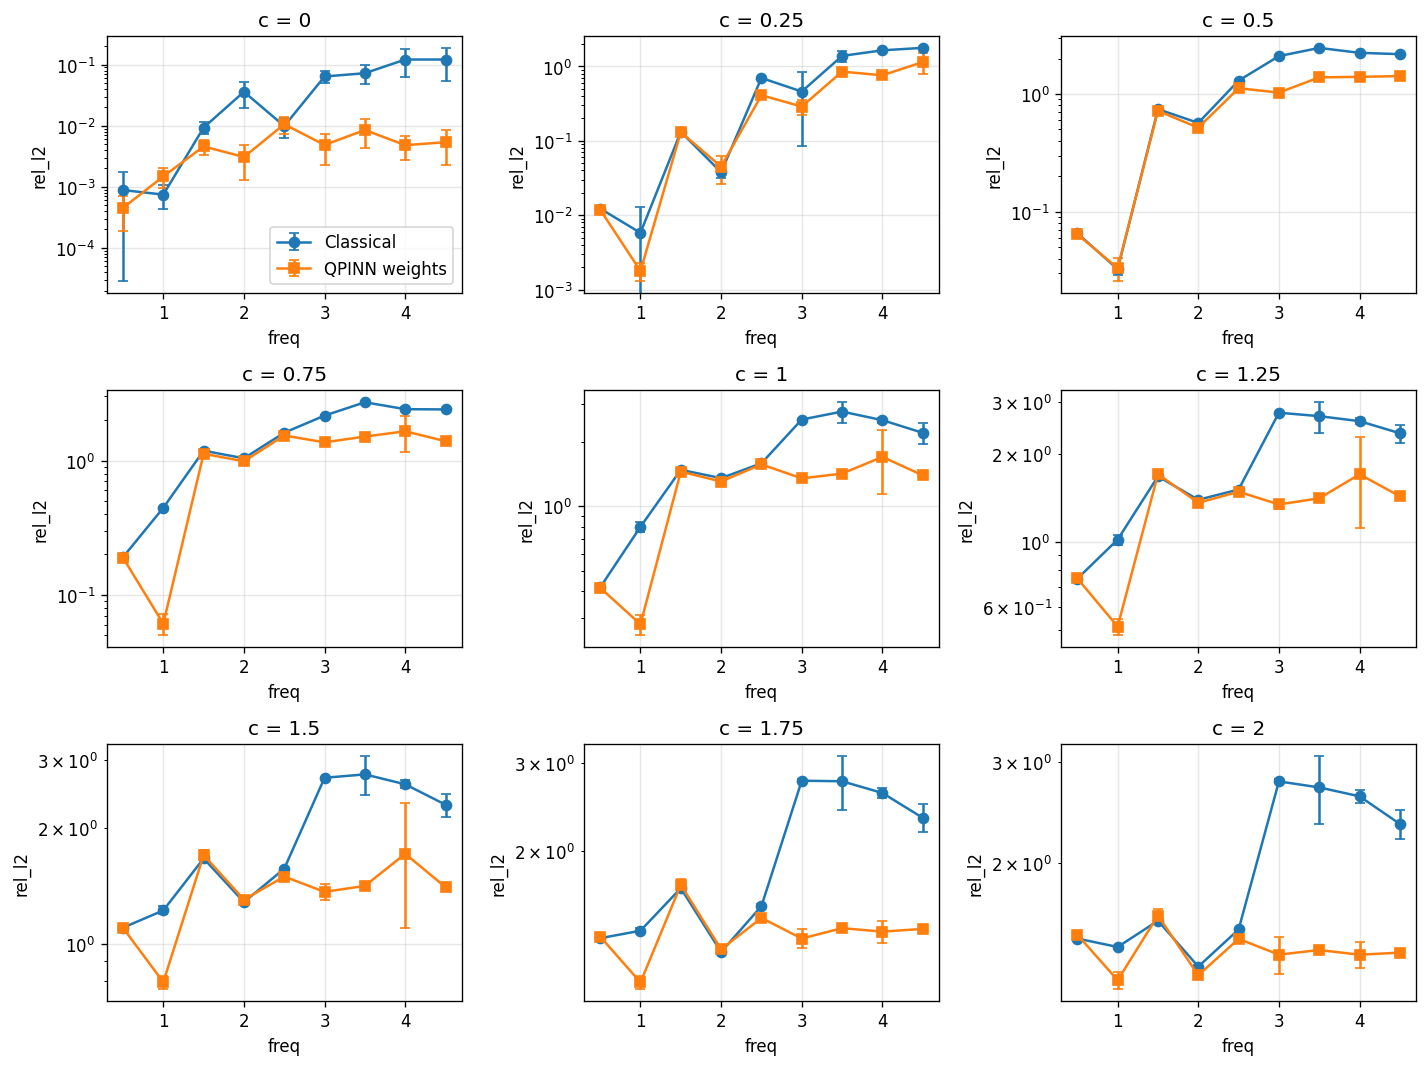

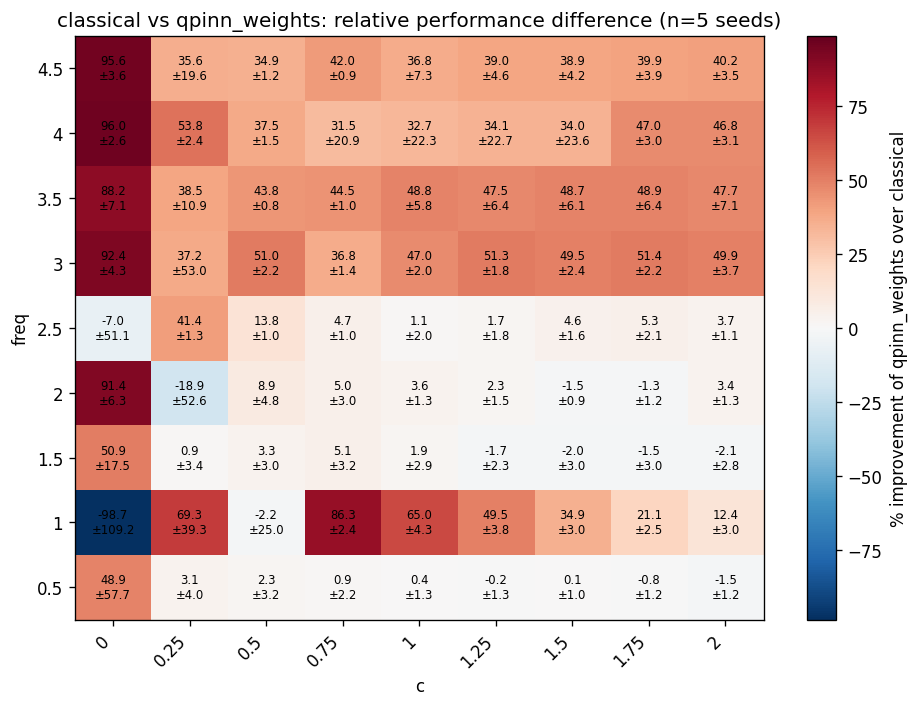

In [29]:
# Raw rel_l2 curves with error bars, faceted by c
plot_rel_l2_curves(sweep_results, FREQUENCIES, C_s)

# Diff heatmap with mean ± std annotated per cell
diff, diff_std = plot_freq_c_performance_diff(
    sweep_results, FREQUENCIES, C_s,
    diff_type="relative",
)

## 2 - Train both models with same frequency and compare

In [8]:
FREQUENCY = 1

In [13]:

#ref_pde = HeatEquation(freq=FREQUENCY)
ref_pde = WaveEquation(freq=FREQUENCY, c=0.0)

# QPINN
qpinn_ref = MerlinHeatQPINN().to(device)
history_q = train(model=qpinn_ref, pde=ref_pde, epochs = 400, seed=120)

# Classical
classical_ref = ClassicalHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, quantum_output_size=QUANTUM_OUTPUT_SIZE, pde = ref_pde).to(device)
history_c = train(model=classical_ref, pde=ref_pde, epochs = 400, seed=120)

qpinn_weights_ref = MerlinTunableSimple(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=ref_pde).to(device)
history_qpinn_weights = train(model=qpinn_weights_ref, pde=ref_pde, epochs = 400, seed=120)

Parameters — total: 250  trainable: 250

Training for 400 epochs on cpu  (dtype=torch.float32)
Epoch     1/400 | Loss: 5.3940e+00 | PDE: 1.19e-05 | Cons: 2.05e-02 | IC: 5.39e-01 | BC: 2.47e-04 | Time: 0.1s
Epoch    50/400 | Loss: 1.4822e+00 | PDE: 7.16e-03 | Cons: 2.02e-02 | IC: 9.76e-02 | BC: 4.97e-01 | Time: 2.5s
Epoch   100/400 | Loss: 3.4940e-01 | PDE: 1.02e-03 | Cons: 2.37e+00 | IC: 5.14e-03 | BC: 5.98e-02 | Time: 5.0s
Epoch   150/400 | Loss: 3.5867e-01 | PDE: 3.52e-03 | Cons: 2.65e+00 | IC: 4.77e-03 | BC: 4.28e-02 | Time: 7.5s
Epoch   200/400 | Loss: 3.4685e-01 | PDE: 1.04e-02 | Cons: 2.17e+00 | IC: 5.88e-03 | BC: 6.05e-02 | Time: 10.0s
Epoch   250/400 | Loss: 2.6930e-01 | PDE: 1.04e-02 | Cons: 1.83e+00 | IC: 3.47e-03 | BC: 4.07e-02 | Time: 12.5s
Epoch   300/400 | Loss: 6.6075e-02 | PDE: 3.24e-03 | Cons: 3.28e-01 | IC: 1.39e-03 | BC: 1.61e-02 | Time: 15.0s
Epoch   350/400 | Loss: 1.7396e-02 | PDE: 8.34e-04 | Cons: 9.51e-02 | IC: 4.12e-04 | BC: 2.93e-03 | Time: 17.5s
Epoch   400/4

In [14]:
# Evaluate models
grid_n = 128


_, U_pred_q, U_true, x_grid, t_grid = evaluate(model=qpinn_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_c, _,      _,      _      = evaluate(model=classical_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_q_w, _,      _,      _      = evaluate(model=qpinn_weights_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

Evaluating on 128×128 grid …
  Relative L2 : 1.5915e-02
  MAE         : 8.9311e-03
  Max abs err : 3.2953e-02
  RMSE        : 1.1209e-02
Evaluating on 128×128 grid …
  Relative L2 : 8.0709e-04
  MAE         : 3.7707e-04
  Max abs err : 1.9622e-03
  RMSE        : 5.6846e-04
Evaluating on 128×128 grid …
  Relative L2 : 1.5257e-03
  MAE         : 7.3991e-04
  Max abs err : 3.3129e-03
  RMSE        : 1.0746e-03


#TODO : figure out here Q error is smaller than C error ??? this doesnt match results from other pipeline

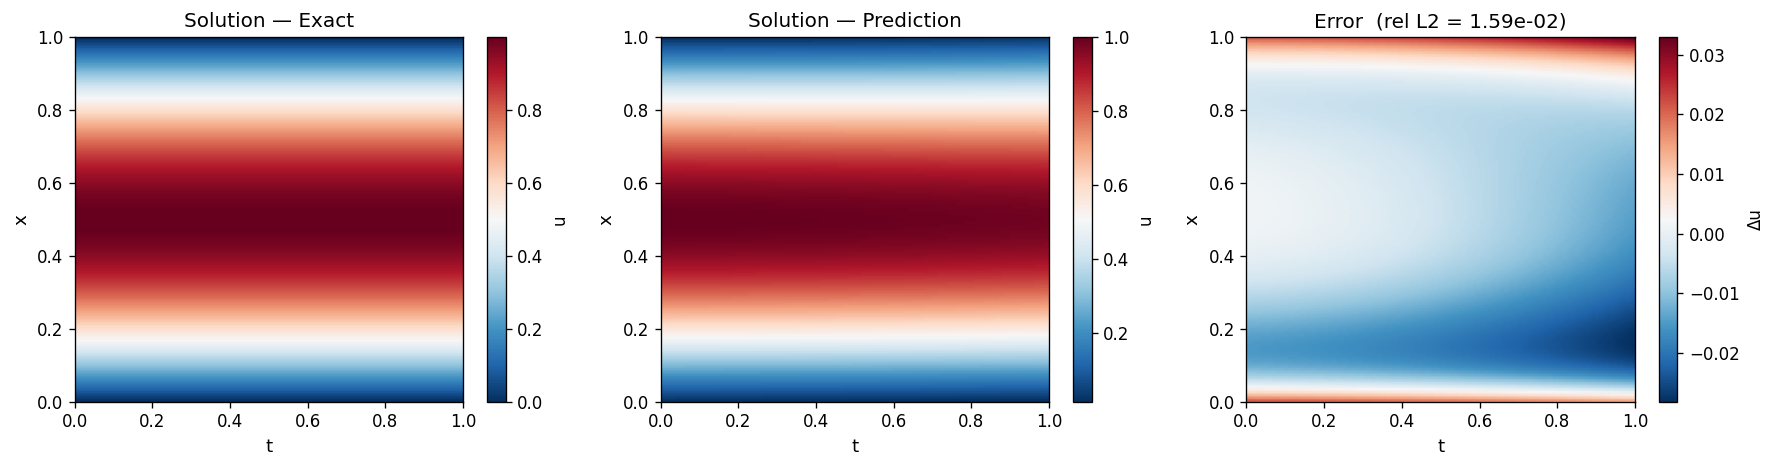

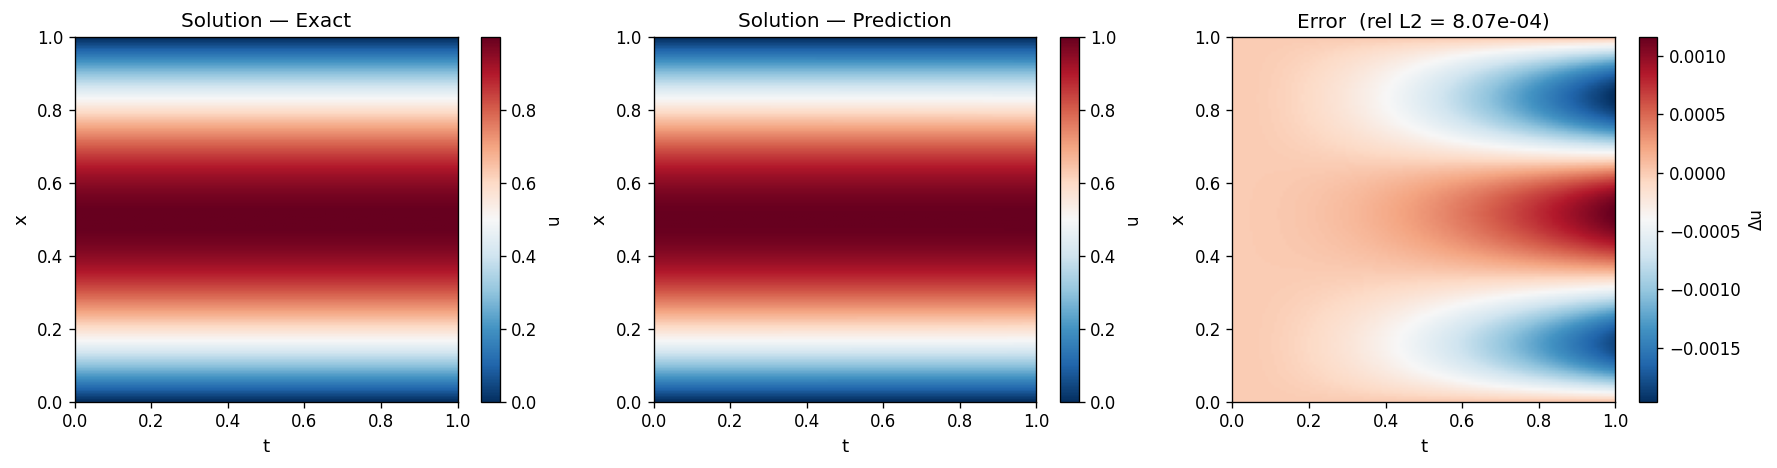

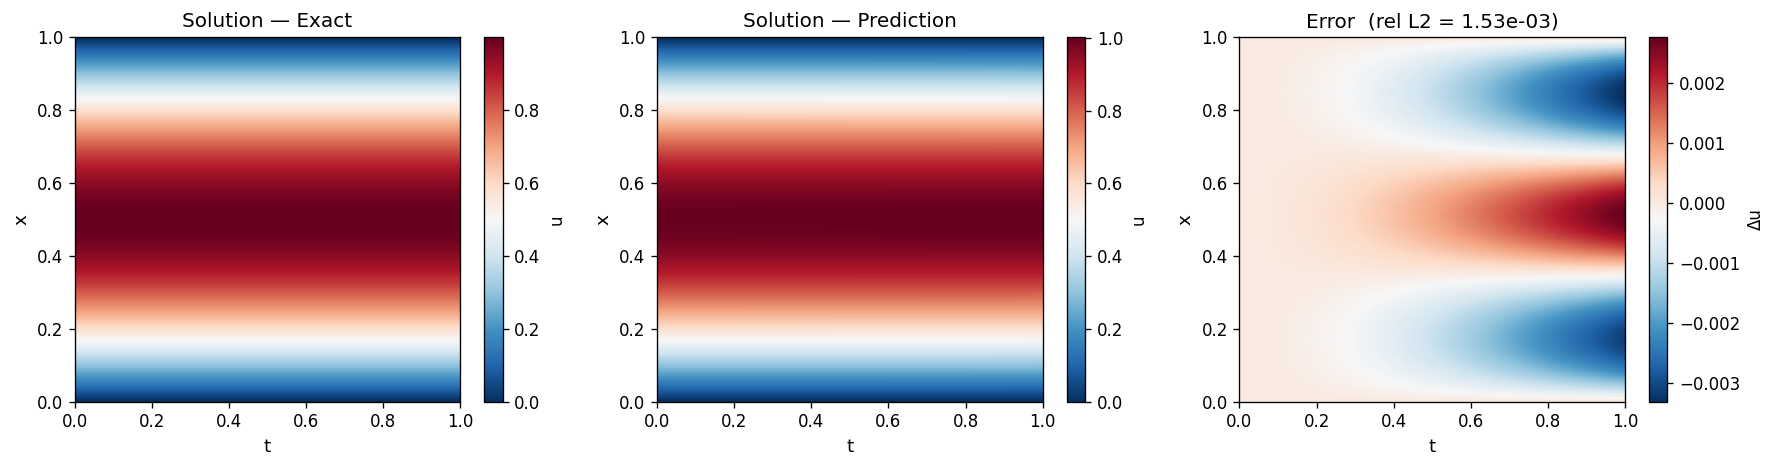

(<Figure size 1800x480 with 6 Axes>, 0.0015256918268278241)

In [15]:
plot_solution_comparison(U_pred_q,U_true)
plot_solution_comparison(U_pred_c,U_true)
plot_solution_comparison(U_pred_q_w,U_true)


### 2.1 - Compare power spectra

QPINN power spectrum
Saved: ../figures/demo_fourier/power_spectrum_q.png


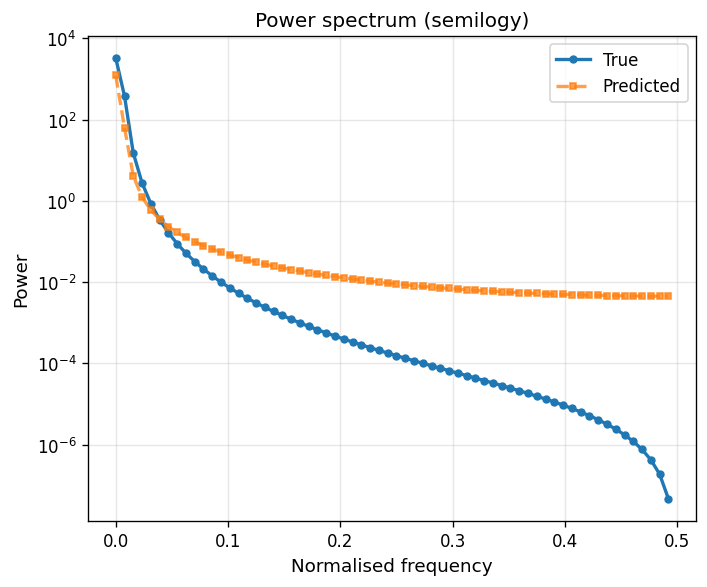

Classical power spectrum
Saved: ../figures/demo_fourier/power_spectrum_c.png


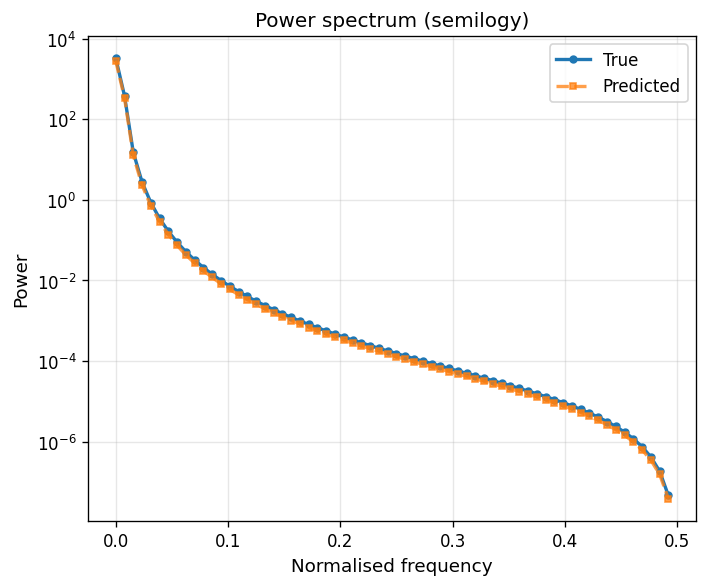

QPINN_weights power spectrum
Saved: ../figures/demo_fourier/power_spectrum_c.png


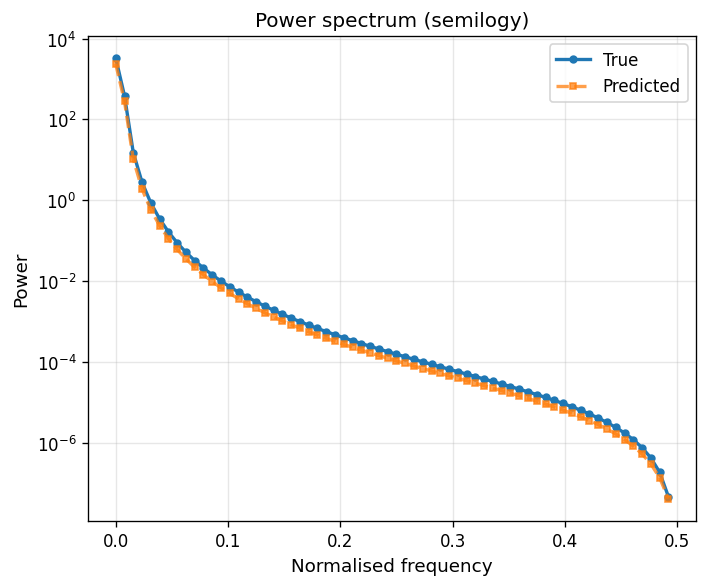

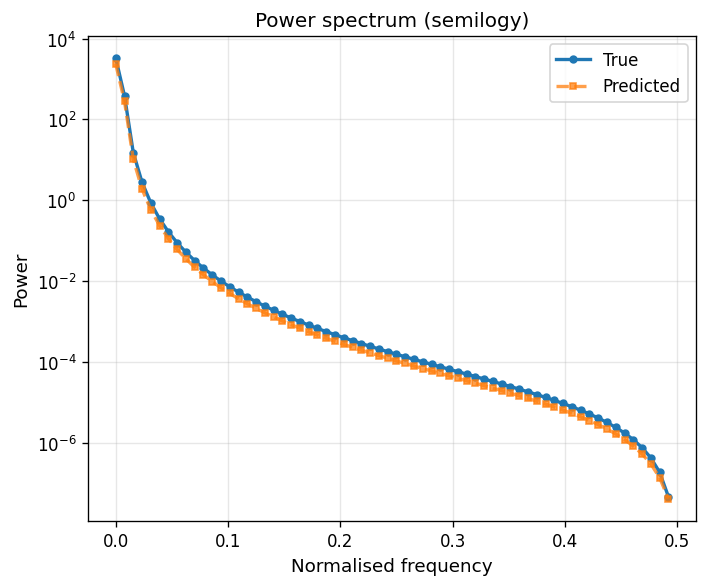

In [77]:
print("QPINN power spectrum")
plot_power_spectrum(U_pred_q, U_true, save_path="../figures/demo_fourier/power_spectrum_q.png", exclude_0_mode=False)

print("Classical power spectrum")
plot_power_spectrum(U_pred_c, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

print("QPINN_weights power spectrum")
plot_power_spectrum(U_pred_q_w, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

### 2.2 Compare per-mode L2 error

QPINN mode errors
Saved: ../figures/fourier_demo/l2_error_Q.png


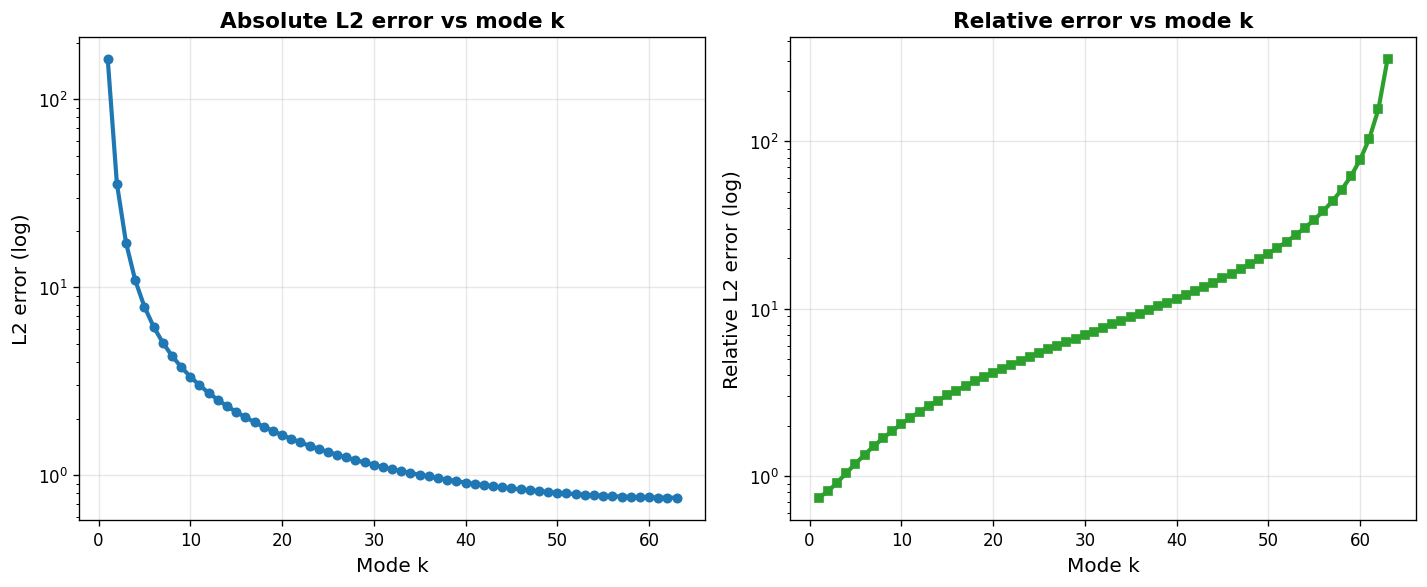

Classical mode errors
Saved: ../figures/fourier_demo/l2_error_C.png


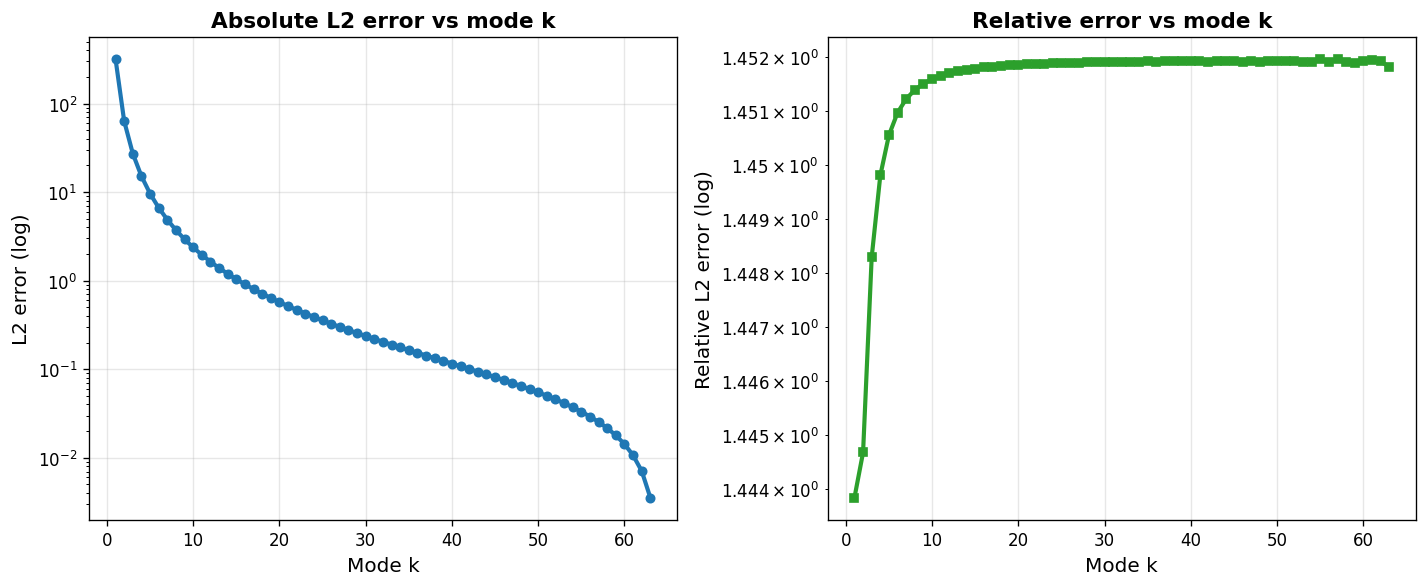

QPINN_weights mode errors
Saved: ../figures/fourier_demo/l2_error_Q_weights.png


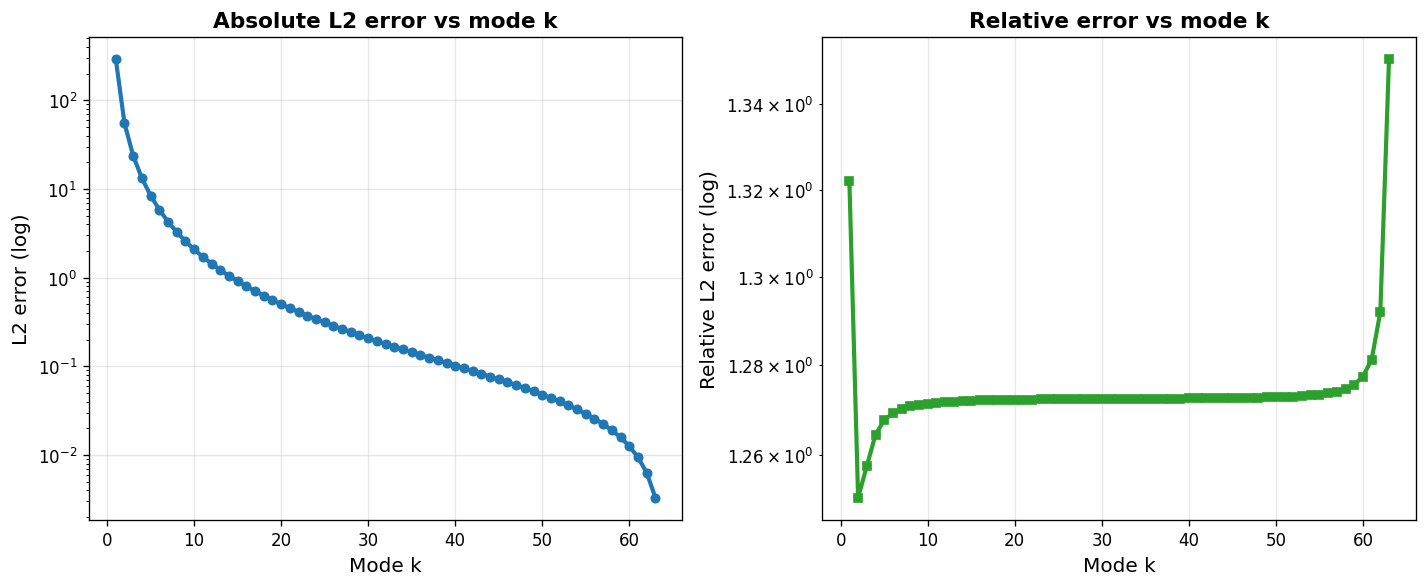

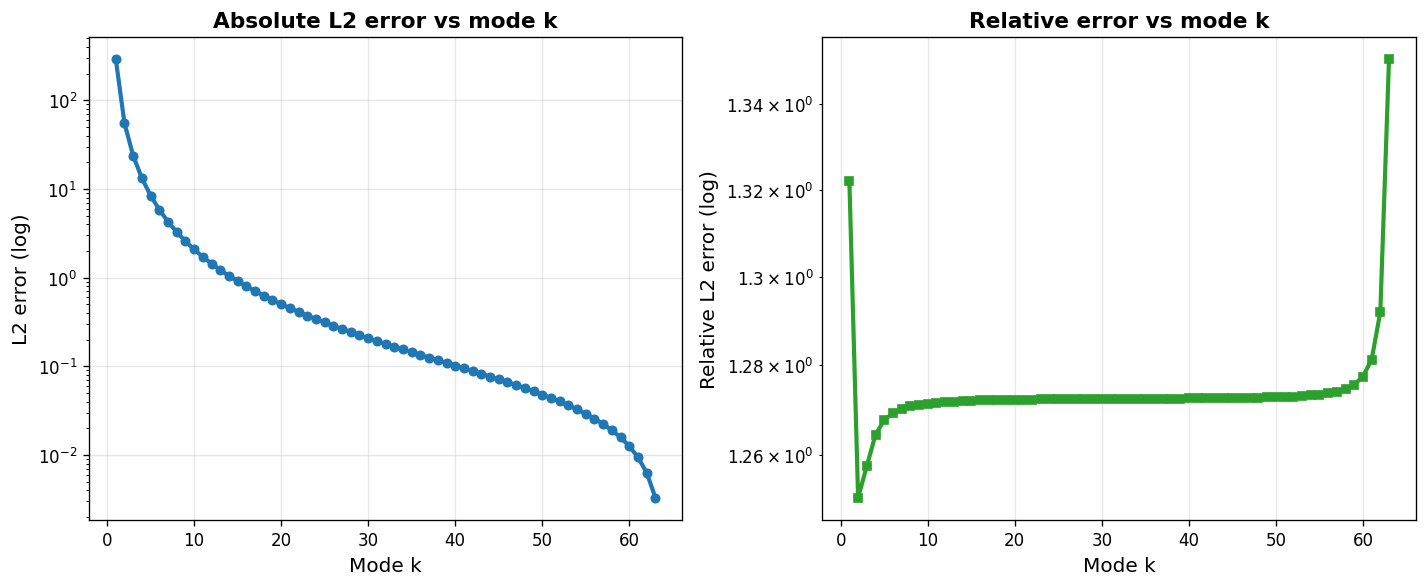

In [78]:
print("QPINN mode errors")
plot_mode_l2_errors(U_pred_q, U_true,
                    save_path="../figures/fourier_demo/l2_error_Q.png")

print("Classical mode errors")
plot_mode_l2_errors(U_pred_c, U_true,
                    save_path="../figures/fourier_demo/l2_error_C.png")

print("QPINN_weights mode errors")
plot_mode_l2_errors(U_pred_q_w, U_true,
                    save_path="../figures/fourier_demo/l2_error_Q_weights.png")



## Compare directly

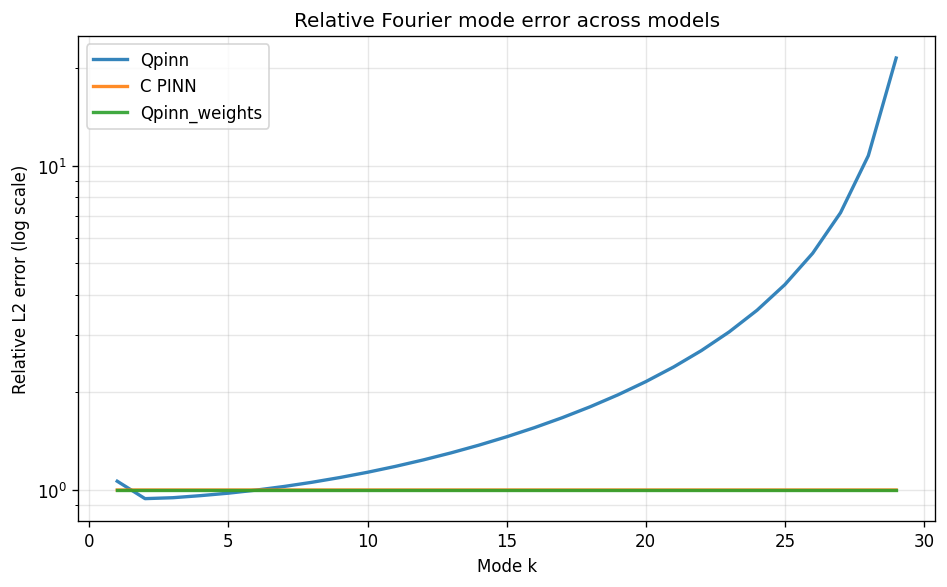

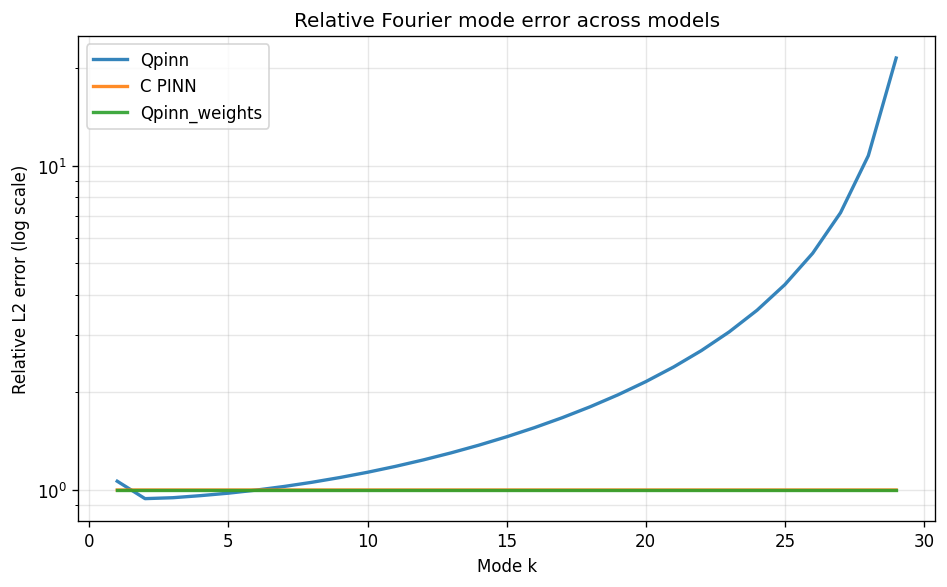

In [16]:


plot_multi_model_l2_error(U_true, [U_pred_q, U_pred_c,U_pred_q_w],["Qpinn", "C PINN","Qpinn_weights"])